In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )
else:
    print("No GPU detected. Check the runtime settings.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/CNN_Colab_Transfer.zip")
DATA_PATH = Path("/content/Data_Normalized")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(DATA_PATH)

print("Extraction completed!")
print("Training directory:", DATA_PATH / "TrainData")
print("Validation directory:", DATA_PATH / "ValidData")


Extraction completed!
Training directory: /content/Data_Normalized/TrainData
Validation directory: /content/Data_Normalized/ValidData


In [ ]:
import os
import h5py
import numpy as np
import torch

from pathlib import Path
from torch.utils.data import Dataset, DataLoader

DATA_PATH = Path("/content/Data_Normalized")

TRAIN_IMG = DATA_PATH / "TrainData" / "img"
TRAIN_MASK = DATA_PATH / "TrainData" / "mask"

VAL_IMG = DATA_PATH / "ValidData" / "img"
VAL_MASK = DATA_PATH / "ValidData" / "mask"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)


Device: cuda


In [ ]:
import re

class LandslideDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)

        # Extract numerical IDs from filenames
        image_files = {
            int(re.search(r"image_(\d+)\.h5", f.name).group(1)): f
            for f in self.image_dir.glob("image_*.h5")
        }

        mask_files = {
            int(re.search(r"mask_(\d+)\.h5", f.name).group(1)): f
            for f in self.mask_dir.glob("mask_*.h5")
        }

        # Check that every image has a corresponding mask
        if image_files.keys() != mask_files.keys():

            missing_masks = image_files.keys() - mask_files.keys()
            missing_images = mask_files.keys() - image_files.keys()

            raise ValueError(
                f"Missing masks: {sorted(missing_masks)[:10]}\n"
                f"Missing images: {sorted(missing_images)[:10]}"
            )

        # Sort by numerical ID and pair
        common_ids = sorted(image_files.keys())

        self.image_files = [image_files[i] for i in common_ids]
        self.mask_files = [mask_files[i] for i in common_ids]

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):

        with h5py.File(self.image_files[index], "r") as f:
            image = f["img"][:]

        with h5py.File(self.mask_files[index], "r") as f:
            mask = f["mask"][:]

        # HWC -> CHW
        image = np.transpose(image, (2, 0, 1))

        image = torch.tensor(image, dtype=torch.float32)
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


In [ ]:
BATCH_SIZE = 8

train_dataset = LandslideDataset(TRAIN_IMG, TRAIN_MASK)
val_dataset = LandslideDataset(VAL_IMG, VAL_MASK)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training samples: 3799
Validation samples: 245
Training batches: 475
Validation batches: 31


In [ ]:
images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Image range:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks))

print("Image GPU transfer test:")
images_gpu = images.to(DEVICE)
print(images_gpu.shape, images_gpu.device)


Image batch shape: torch.Size([8, 6, 128, 128])
Mask batch shape: torch.Size([8, 1, 128, 128])
Image dtype: torch.float32
Mask dtype: torch.float32
Image range: -1.9810365438461304 11.95154094696045
Mask values: tensor([0., 1.])
Image GPU transfer test:
torch.Size([8, 6, 128, 128]) cuda:0


**Why U-Net for landslide mapping?**
Your Random Forest treated each pixel largely as an independent spectral observation. U-Net takes a different approach: it learns both:
- Spectral information: How B2, B3, B4, B8, B11 and B12 behave.
- Spatial information: How neighbouring pixels form patterns, boundaries, textures and terrain features.

**The architecture has three important components:**
1. Encoder: Extracts increasingly complex features while reducing spatial dimensions.
2. Bottleneck: Learns high-level representations.
3. Decoder: Reconstructs the spatial resolution to produce a pixel-level landslide mask.

In [ ]:
import torch
import torch.nn as nn

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

**Encoder** — feature extraction and downsampling

In [ ]:
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = ConvBlock(6, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.bottleneck = ConvBlock(256, 512)
    def forward(self, x):

      e1 = self.enc1(x)
      e2 = self.enc2(self.pool(e1))
      e3 = self.enc3(self.pool(e2))
      e4 = self.enc4(self.pool(e3))

      b = self.bottleneck(self.pool(e4))

      return e1, e2, e3, e4, b

In [ ]:
# Testing the Encoder
encoder = Encoder().to(DEVICE)

x = torch.randn(8, 6, 128, 128).to(DEVICE)

e1, e2, e3, e4, b = encoder(x)

print("E1:", e1.shape)
print("E2:", e2.shape)
print("E3:", e3.shape)
print("E4:", e4.shape)
print("Bottleneck input:", b.shape)

E1: torch.Size([8, 32, 128, 128])
E2: torch.Size([8, 64, 64, 64])
E3: torch.Size([8, 128, 32, 32])
E4: torch.Size([8, 256, 16, 16])
Bottleneck input: torch.Size([8, 512, 8, 8])


In [ ]:
class Decoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(64, 32)

    def forward(self, e1, e2, e3, e4, b):

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return d1

In [ ]:
#Testing the decoder
decoder = Decoder().to(DEVICE)

# Generate dummy encoder outputs
e1 = torch.randn(8, 32, 128, 128).to(DEVICE)
e2 = torch.randn(8, 64, 64, 64).to(DEVICE)
e3 = torch.randn(8, 128, 32, 32).to(DEVICE)
e4 = torch.randn(8, 256, 16, 16).to(DEVICE)
b  = torch.randn(8, 512, 8, 8).to(DEVICE)

output = decoder(e1, e2, e3, e4, b)

print("Decoder output:", output.shape)

Decoder output: torch.Size([8, 32, 128, 128])


**Assemble the complete U-Net**

In [ ]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = Encoder()
        self.decoder = Decoder()

        self.final_conv = nn.Conv2d(
            in_channels=32,
            out_channels=1,
            kernel_size=1
        )

    def forward(self, x):

        e1, e2, e3, e4, b = self.encoder(x)

        d1 = self.decoder(e1, e2, e3, e4, b)

        output = self.final_conv(d1)

        return output

In [ ]:
model = UNet().to(DEVICE)

x = torch.randn(8, 6, 128, 128).to(DEVICE)

output = model(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Model device:", next(model.parameters()).device)

Input shape: torch.Size([8, 6, 128, 128])
Output shape: torch.Size([8, 1, 128, 128])
Model device: cuda:0


**Learning Mechanism**

Our network needs three things:
1. Loss function: Measures how far predictions are from the reference masks.
2. Optimizer: Updates the network's weights to reduce that loss.
3. Evaluation metrics: Measures how well the model identifies landslide pixels.

In [ ]:
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):

        bce_loss = self.bce(logits, targets)

        probabilities = torch.sigmoid(logits)

        smooth = 1e-6

        intersection = (probabilities * targets).sum(dim=(1, 2, 3))

        denominator = (
            probabilities.sum(dim=(1, 2, 3))
            + targets.sum(dim=(1, 2, 3))
        )

        dice = (2 * intersection + smooth) / (denominator + smooth)

        dice_loss = 1 - dice.mean()

        return bce_loss + dice_loss

In [ ]:
criterion = BCEDiceLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
images, masks = next(iter(train_loader))

images = images.to(DEVICE)
masks = masks.to(DEVICE)

logits = model(images)

loss = criterion(logits, masks)

print("Logits shape:", logits.shape)
print("Mask shape:", masks.shape)
print("Initial loss:", loss.item())

Logits shape: torch.Size([8, 1, 128, 128])
Mask shape: torch.Size([8, 1, 128, 128])
Initial loss: 1.710322618484497


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        logits = model(images)

        # Calculate loss
        loss = criterion(logits, masks)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(loader)

    return epoch_loss

In [ ]:
train_loss = train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    DEVICE
)

print("Training loss:", train_loss)

Training loss: 0.9909252287212171


In [ ]:
def validate_one_epoch(model, loader, criterion, device, threshold=0.5):

    model.eval()

    running_loss = 0.0

    TP = 0
    FP = 0
    TN = 0
    FN = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            # Forward propagation
            logits = model(images)

            # Validation loss
            loss = criterion(logits, masks)

            running_loss += loss.item() * images.size(0)

            # Convert logits to probabilities
            probabilities = torch.sigmoid(logits)

            # Convert probabilities into binary predictions
            predictions = (probabilities >= threshold).float()

            # Count confusion matrix elements
            TP += ((predictions == 1) & (masks == 1)).sum().item()
            FP += ((predictions == 1) & (masks == 0)).sum().item()
            TN += ((predictions == 0) & (masks == 0)).sum().item()
            FN += ((predictions == 0) & (masks == 1)).sum().item()

    val_loss = running_loss / len(loader.dataset)

    precision = TP / (TP + FP + 1e-8)
    recall = TP / (TP + FN + 1e-8)

    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    iou = TP / (TP + FP + FN + 1e-8)

    return val_loss, precision, recall, f1, iou

In [ ]:
val_loss, precision, recall, f1, iou = validate_one_epoch(
    model,
    val_loader,
    criterion,
    DEVICE,
    threshold=0.5
)

print("Validation Loss:", val_loss)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("IoU:", iou)

Validation Loss: 0.8494702835472263
Precision: 0.28682820161969536
Recall: 0.6372972579823061
F1 Score: 0.3956060782156631
IoU: 0.246576653140235


In [ ]:
import copy

EPOCHS = 10

best_f1 = f1  # Current epoch-1 validation F1

best_model_state = copy.deepcopy(model.state_dict())

torch.save({
    "epoch": 1,
    "model_state_dict": best_model_state,
    "optimizer_state_dict": optimizer.state_dict(),
    "best_f1": best_f1
}, "/content/best_unet.pth")

history = [{
    "epoch": 1,
    "train_loss": train_loss,
    "val_loss": val_loss,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "iou": iou
}]

for epoch in range(2, EPOCHS + 1):

    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE
    )

    val_loss, precision, recall, f1, iou = validate_one_epoch(
        model, val_loader, criterion, DEVICE, threshold=0.5
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou
    })

    print(
        f"Epoch [{epoch}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f} | "
        f"IoU: {iou:.4f}"
    )

    if f1 > best_f1:

        best_f1 = f1

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_f1": best_f1
        }, "/content/best_unet.pth")

        print("  -> Best model checkpoint saved!")

print("\nBest validation F1:", best_f1)

Epoch [2/10] | Train Loss: 0.7929 | Val Loss: 0.8172 | Precision: 0.4294 | Recall: 0.5662 | F1: 0.4884 | IoU: 0.3231
  -> Best model checkpoint saved!
Epoch [3/10] | Train Loss: 0.7708 | Val Loss: 0.8127 | Precision: 0.5085 | Recall: 0.4397 | F1: 0.4716 | IoU: 0.3086
Epoch [4/10] | Train Loss: 0.7580 | Val Loss: 0.7628 | Precision: 0.3890 | Recall: 0.6838 | F1: 0.4959 | IoU: 0.3297
  -> Best model checkpoint saved!
Epoch [5/10] | Train Loss: 0.7531 | Val Loss: 0.7899 | Precision: 0.5183 | Recall: 0.4201 | F1: 0.4640 | IoU: 0.3021
Epoch [6/10] | Train Loss: 0.7482 | Val Loss: 0.8659 | Precision: 0.5275 | Recall: 0.2278 | F1: 0.3182 | IoU: 0.1892
Epoch [7/10] | Train Loss: 0.7433 | Val Loss: 0.7860 | Precision: 0.5042 | Recall: 0.5033 | F1: 0.5037 | IoU: 0.3367
  -> Best model checkpoint saved!
Epoch [8/10] | Train Loss: 0.7386 | Val Loss: 0.8317 | Precision: 0.5611 | Recall: 0.4651 | F1: 0.5086 | IoU: 0.3410
  -> Best model checkpoint saved!
Epoch [9/10] | Train Loss: 0.7387 | Val Loss:

Restoring best model: epoch 8

In [ ]:
checkpoint = torch.load(
    "/content/best_unet.pth",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

model.eval()

print("Restored epoch:", checkpoint["epoch"])
print("Best validation F1:", checkpoint["best_f1"])


Restored epoch: 8
Best validation F1: 0.5085896937679164


In [ ]:

model.eval()

all_probs = []
all_masks = []

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)

        logits = model(images)
        probabilities = torch.sigmoid(logits)

        all_probs.append(probabilities.cpu().numpy())
        all_masks.append(masks.numpy())

all_probs = np.concatenate(all_probs, axis=0)
all_masks = np.concatenate(all_masks, axis=0)

print("Probability array:", all_probs.shape)
print("Mask array:", all_masks.shape)

Probability array: (245, 1, 128, 128)
Mask array: (245, 1, 128, 128)


In [ ]:
import pandas as pd

# Convert reference masks into binary labels
y_true = (all_masks >= 0.5)

thresholds = np.arange(0.10, 0.91, 0.05)
results = []

for threshold in thresholds:

    # Convert probabilities into binary predictions
    y_pred = (all_probs >= threshold)

    # Calculate confusion matrix components
    TP = np.sum(y_pred & y_true)
    FP = np.sum(y_pred & ~y_true)
    FN = np.sum(~y_pred & y_true)

    # Calculate metrics
    precision = TP / (TP + FP + 1e-8)
    recall = TP / (TP + FN + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = TP / (TP + FP + FN + 1e-8)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou
    })

# Display results
threshold_df = pd.DataFrame(results)

print(threshold_df.round(8).to_string(index=False))

# Identify threshold with highest validation F1
best_idx = threshold_df["F1"].idxmax()
best_row = threshold_df.loc[best_idx]

print("\nBest validation threshold:")
print(best_row.round(8))

 Threshold  Precision   Recall       F1      IoU
      0.10   0.447916 0.630999 0.523924 0.354944
      0.15   0.475153 0.592087 0.527214 0.357970
      0.20   0.493949 0.564070 0.526686 0.357484
      0.25   0.507741 0.542425 0.524510 0.355482
      0.30   0.520386 0.524315 0.522343 0.353494
      0.35   0.532184 0.508735 0.520195 0.351530
      0.40   0.542803 0.494101 0.517309 0.348898
      0.45   0.552458 0.479657 0.513490 0.345433
      0.50   0.561058 0.465096 0.508590 0.341013
      0.55   0.570237 0.451378 0.503893 0.336803
      0.60   0.580363 0.437486 0.498897 0.332353
      0.65   0.590007 0.420845 0.491272 0.325620
      0.70   0.600291 0.402080 0.481588 0.317166
      0.75   0.611550 0.378326 0.467463 0.305026
      0.80   0.624948 0.347342 0.446514 0.287427
      0.85   0.645484 0.304080 0.413408 0.260564
      0.90   0.672170 0.248716 0.363084 0.221810

Best validation threshold:
Threshold    0.150000
Precision    0.475153
Recall       0.592087
F1           0.527214
Io

In [ ]:
fine_thresholds = np.arange(0.10, 0.251, 0.005)
fine_results = []

for threshold in fine_thresholds:
    y_pred = all_probs >= threshold

    TP = np.sum(y_pred & y_true)
    FP = np.sum(y_pred & ~y_true)
    FN = np.sum(~y_pred & y_true)

    precision = TP / (TP + FP + 1e-8)
    recall = TP / (TP + FN + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = TP / (TP + FP + FN + 1e-8)

    fine_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou
    })

fine_df = pd.DataFrame(fine_results)

best_idx = fine_df["F1"].idxmax()
best_threshold = fine_df.loc[best_idx, "Threshold"]

print(fine_df.round(8).to_string(index=False))
print("\nRefined best threshold:", round(best_threshold, 3))
print(fine_df.loc[best_idx].round(4))

 Threshold  Precision   Recall       F1      IoU
     0.100   0.447916 0.630999 0.523924 0.354944
     0.105   0.451367 0.626300 0.524636 0.355597
     0.110   0.454844 0.621922 0.525421 0.356319
     0.115   0.457713 0.617529 0.525744 0.356617
     0.120   0.460409 0.613805 0.526154 0.356994
     0.125   0.462884 0.609819 0.526288 0.357117
     0.130   0.465408 0.605630 0.526340 0.357165
     0.135   0.468106 0.602167 0.526740 0.357534
     0.140   0.470459 0.598618 0.526857 0.357641
     0.145   0.472890 0.595403 0.527122 0.357885
     0.150   0.475153 0.592087 0.527214 0.357970
     0.155   0.477384 0.589076 0.527381 0.358124
     0.160   0.479387 0.585759 0.527261 0.358014
     0.165   0.481390 0.582864 0.527290 0.358040
     0.170   0.482977 0.579664 0.526922 0.357701
     0.175   0.485256 0.577133 0.527222 0.357977
     0.180   0.486877 0.574253 0.526968 0.357744
     0.185   0.488358 0.571169 0.526528 0.357338
     0.190   0.490161 0.568856 0.526584 0.357390
     0.195   0.49231

In [ ]:
#Loading Test data
ZIP_PATH = "/content/CNN_TestData.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall("/content/Data_Normalized")

print("Test data extracted successfully!")

TEST_IMG = Path("/content/Data_Normalized/TestData/img")
TEST_MASK = Path("/content/Data_Normalized/TestData/mask")

print("Images:", len(list(TEST_IMG.glob("image_*.h5"))))
print("Masks:", len(list(TEST_MASK.glob("mask_*.h5"))))

Test data extracted successfully!
Images: 800
Masks: 800


In [ ]:
TEST_IMG = Path("/content/Data_Normalized/TestData/img")
TEST_MASK = Path("/content/Data_Normalized/TestData/mask")

test_dataset = LandslideDataset(TEST_IMG, TEST_MASK)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Verified test image-mask pairs:", len(test_dataset))
print("Test batches:", len(test_loader))

Verified test image-mask pairs: 800
Test batches: 100


In [ ]:
# Restore the selected checkpoint once more
checkpoint = torch.load(
    "/content/best_unet.pth",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Frozen validation-selected threshold
TEST_THRESHOLD = 0.155

test_loss, test_precision, test_recall, test_f1, test_iou = (
    validate_one_epoch(
        model,
        test_loader,
        criterion,
        DEVICE,
        threshold=TEST_THRESHOLD
    )
)

print("\n========== FINAL U-NET TEST RESULTS ==========")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Threshold:", TEST_THRESHOLD)
print("Test loss:", round(test_loss, 8))
print("Precision:", round(test_precision, 8))
print("Recall:", round(test_recall, 8))
print("F1:", round(test_f1, 8))
print("IoU:", round(test_iou, 8))


========== FINAL U-NET TEST RESULTS ==========
Checkpoint epoch: 8
Threshold: 0.155
Test loss: 0.81848933
Precision: 0.45926431
Recall: 0.55478304
F1: 0.50252495
IoU: 0.33558152


In [ ]:
MODEL_DIR = Path("/content/Ablation_Results")
MODEL_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:
import shutil
from pathlib import Path

def transfer_file(source_file, target_folder, copy_only=False):
    src = Path(source_file)
    dest_dir = Path(target_folder)
    if not src.exists():
        print(f"Error: Source file '{src}' does not exist.")
        return

    # Ensure target folder exists
    dest_dir.mkdir(parents=True, exist_ok=True)
    dest_path = dest_dir / src.name

    if copy_only:
        shutil.copy2(src, dest_path)
        print(f"Successfully copied: {src} -> {dest_path}")
    else:
        shutil.move(str(src), str(dest_path))
        print(f"Successfully moved: {src} -> {dest_path}")

# Example usage:
# transfer_file("/content/M1_RGB.joblib", "/content/Ablation_Results", copy_only=True)

In [ ]:
transfer_file("/content/M2_RGB_NIR.joblib", "/content/Ablation_Results", copy_only=True)
transfer_file("/content/M3_RGB_NIR_SWIR1.joblib", "/content/Ablation_Results", copy_only=True)
transfer_file("/content/M4_ALL_SIX.joblib", "/content/Ablation_Results", copy_only=True)
transfer_file("/content/ablation_metadata.json", "/content/Ablation_Results", copy_only=True)
transfer_file("/content/training_sample.npz", "/content/Ablation_Results", copy_only=True)
transfer_file("/content/M1_RGB.joblib", "/content/Ablation_Results", copy_only=True)

Successfully copied: /content/M2_RGB_NIR.joblib -> /content/Ablation_Results/M2_RGB_NIR.joblib
Successfully copied: /content/M3_RGB_NIR_SWIR1.joblib -> /content/Ablation_Results/M3_RGB_NIR_SWIR1.joblib
Successfully copied: /content/M4_ALL_SIX.joblib -> /content/Ablation_Results/M4_ALL_SIX.joblib
Successfully copied: /content/ablation_metadata.json -> /content/Ablation_Results/ablation_metadata.json
Successfully copied: /content/training_sample.npz -> /content/Ablation_Results/training_sample.npz
Successfully copied: /content/M1_RGB.joblib -> /content/Ablation_Results/M1_RGB.joblib


In [ ]:
from pathlib import Path

checkpoint_path = Path("/content/best_unet.pth")

print("Checkpoint exists:", checkpoint_path.exists())

Checkpoint exists: True


In [ ]:
# Create a fresh U-Net instance
unet_model = UNet().to(DEVICE)

# Load the best epoch-4 checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

# Restore weights
unet_model.load_state_dict(checkpoint["model_state_dict"])

unet_model.eval()

print("U-Net restored successfully.")
print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Model type:", type(unet_model))

U-Net restored successfully.
Checkpoint epoch: 8
Model type: <class '__main__.UNet'>


In [ ]:
import joblib
from torch.utils.data import DataLoader

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

MODEL_DIR = Path("/content/Ablation_Results")

RF_CONFIG = {
    "M1_RGB": {
        "file": "M1_RGB.joblib",
        "bands": [0, 1, 2],
        "threshold": 0.825
    },
    "M2_RGB_NIR": {
        "file": "M2_RGB_NIR.joblib",
        "bands": [0, 1, 2, 3],
        "threshold": 0.900
    },
    "M3_RGB_NIR_SWIR1": {
        "file": "M3_RGB_NIR_SWIR1.joblib",
        "bands": [0, 1, 2, 3, 4],
        "threshold": 0.875
    },
    "M4_ALL_SIX": {
        "file": "M4_ALL_SIX.joblib",
        "bands": [0, 1, 2, 3, 4, 5],
        "threshold": 0.850
    }
}

UNET_THRESHOLD = 0.155

# Ensure deterministic test order
test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

N = len(test_dataset)
H, W = 128, 128

# --------------------------------------------------
# 2. Load RF models
# --------------------------------------------------

rf_models = {}

for name, config in RF_CONFIG.items():
    path = MODEL_DIR / config["file"]

    rf_models[name] = joblib.load(
        MODEL_DIR / config["file"]
    )

    print(
        name,
        "| Features:", rf_models[name].n_features_in_,
        "| Threshold:", config["threshold"]
    )

# --------------------------------------------------
# 3. Allocate prediction arrays
# --------------------------------------------------

model_names = list(RF_CONFIG.keys()) + ["U-Net"]

predictions = {
    name: np.zeros((N, H, W), dtype=np.uint8)
    for name in model_names
}

test_masks = np.zeros((N, H, W), dtype=np.uint8)

# --------------------------------------------------
# 4. Inference
# --------------------------------------------------

# Move only the U-Net to the selected device
unet_model.eval()
start = 0

with torch.no_grad():

    for images, masks in test_loader:

        batch_size = images.shape[0]
        end = start + batch_size

        # Ground truth
        gt = masks.squeeze(1).numpy() >= 0.5
        test_masks[start:end] = gt.astype(np.uint8)

        # Convert image batch from BCHW to B,H,W,C
        images_np = images.numpy()
        images_hwc = np.transpose(images_np, (0, 2, 3, 1))

        # Flatten all pixels in the batch
        flat_pixels = images_hwc.reshape(-1, 6)

        # --------------------------
        # Random Forest predictions
        # --------------------------

        for name, config in RF_CONFIG.items():

            selected_bands = config["bands"]

            probabilities = rf_models[name].predict_proba(
                flat_pixels[:, selected_bands]
            )[:, 1]

            probabilities = probabilities.reshape(
                batch_size, H, W
            )

            predictions[name][start:end] = (
                probabilities >= config["threshold"]
            ).astype(np.uint8)

        # --------------------------
        # U-Net predictions
        # --------------------------

        images_gpu = images.to(DEVICE)

        logits = unet_model(images_gpu)
        probabilities = torch.sigmoid(logits)

        unet_predictions = (
            probabilities >= UNET_THRESHOLD
        ).squeeze(1).cpu().numpy()

        predictions["U-Net"][start:end] = (
            unet_predictions.astype(np.uint8)
        )

        start = end

        if start % 80 == 0 or start == N:
            print(f"Processed {start}/{N} test patches")

print("\nAll five models completed inference.")

# --------------------------------------------------
# 5. Save predictions
# --------------------------------------------------

np.savez_compressed(
    "/content/all_model_predictions.npz",
    test_masks=test_masks,
    **predictions
)

print("Predictions saved successfully.")


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


M1_RGB | Features: 3 | Threshold: 0.825
M2_RGB_NIR | Features: 4 | Threshold: 0.9
M3_RGB_NIR_SWIR1 | Features: 5 | Threshold: 0.875
M4_ALL_SIX | Features: 6 | Threshold: 0.85
Processed 80/800 test patches
Processed 160/800 test patches
Processed 240/800 test patches
Processed 320/800 test patches
Processed 400/800 test patches
Processed 480/800 test patches
Processed 560/800 test patches
Processed 640/800 test patches
Processed 720/800 test patches
Processed 800/800 test patches

All five models completed inference.
Predictions saved successfully.


In [ ]:
print("Ground truth:", test_masks.shape)

for name, pred in predictions.items():
    print(name, pred.shape, "Positive pixels:", pred.sum())

Ground truth: (800, 128, 128)
M1_RGB (800, 128, 128) Positive pixels: 450237
M2_RGB_NIR (800, 128, 128) Positive pixels: 320179
M3_RGB_NIR_SWIR1 (800, 128, 128) Positive pixels: 312749
M4_ALL_SIX (800, 128, 128) Positive pixels: 379600
U-Net (800, 128, 128) Positive pixels: 299013


Ground truth shape: (800, 128, 128)
M1_RGB (800, 128, 128)
M2_RGB_NIR (800, 128, 128)
M3_RGB_NIR_SWIR1 (800, 128, 128)
M4_ALL_SIX (800, 128, 128)
U-Net (800, 128, 128)

Selected test patches:
Patch 2: 0.000% landslide coverage
Patch 320: 0.006% landslide coverage
Patch 32: 1.154% landslide coverage
Patch 641: 88.348% landslide coverage


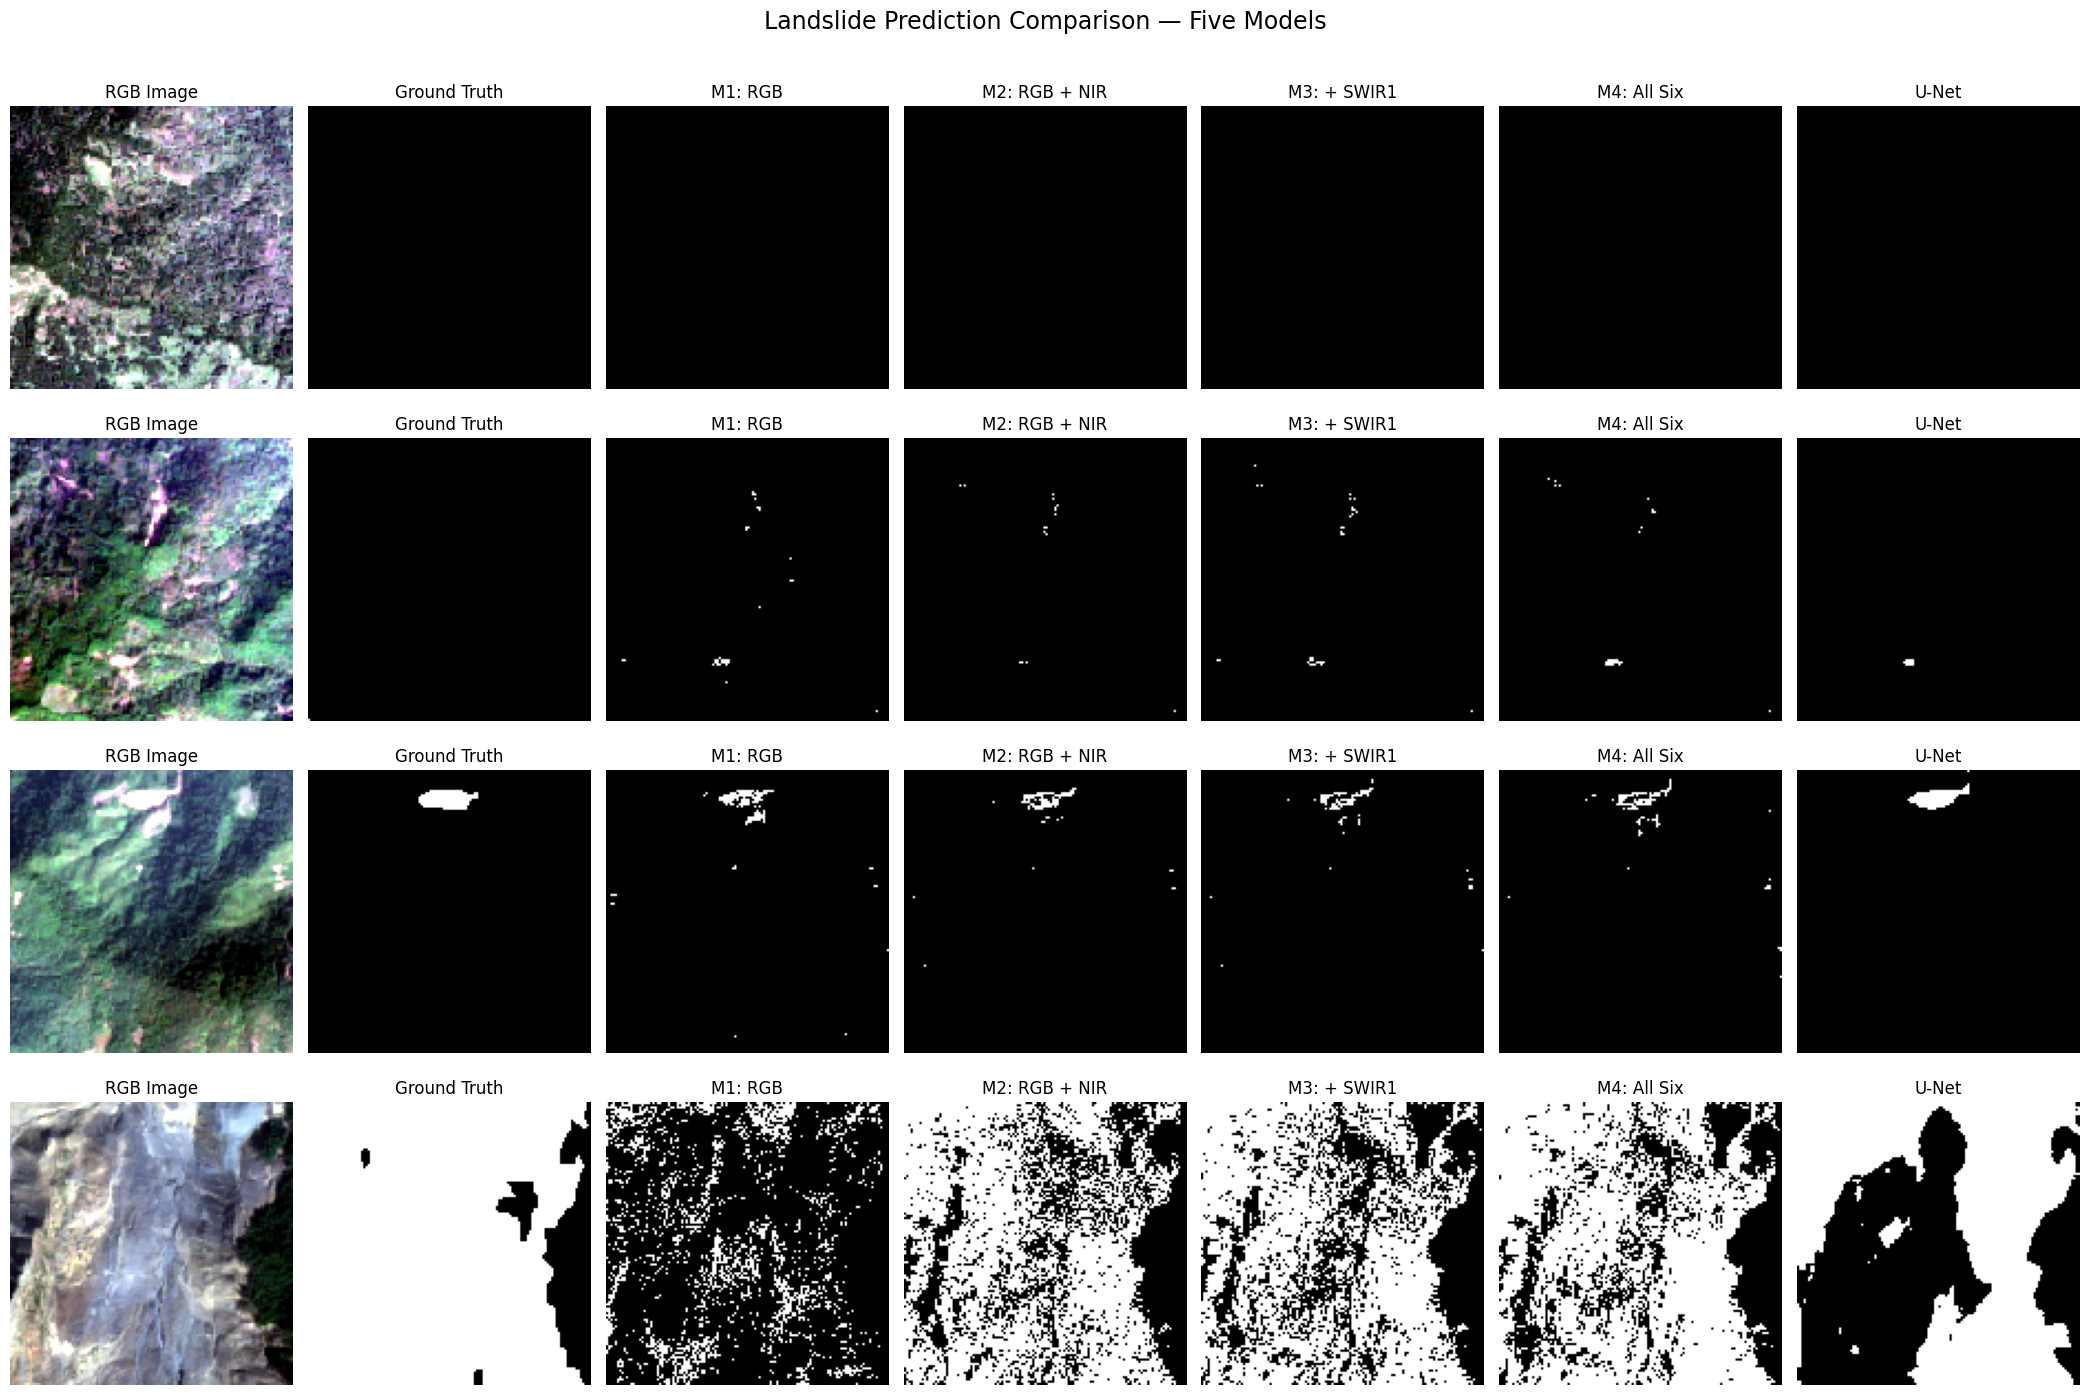

Figure 1 saved successfully.


In [ ]:
#Preditction Comparison
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Verify inference outputs
# --------------------------------------------------

print("Ground truth shape:", test_masks.shape)

for name, pred in predictions.items():
    print(name, pred.shape)

assert test_masks.shape == (800, 128, 128)

for name, pred in predictions.items():
    assert pred.shape == test_masks.shape, f"Shape mismatch: {name}"

# --------------------------------------------------
# 2. Select representative test patches
# --------------------------------------------------

# Fraction of landslide pixels in each patch
fractions = test_masks.mean(axis=(1, 2))

zero_indices = np.where(fractions == 0)[0]
positive_indices = np.where(fractions > 0)[0]

if len(positive_indices) == 0:
    raise ValueError("No positive test patches found.")

selected = []

# Patch with no landslide pixels, if available
if len(zero_indices) > 0:
    selected.append(zero_indices[0])

# Minimum positive coverage
selected.append(positive_indices[np.argmin(fractions[positive_indices])])

# Median positive coverage
median_value = np.median(fractions[positive_indices])
median_idx = positive_indices[
    np.argmin(np.abs(fractions[positive_indices] - median_value))
]
selected.append(median_idx)

# Maximum positive coverage
selected.append(positive_indices[np.argmax(fractions[positive_indices])])

# Remove duplicates while preserving order
selected = list(dict.fromkeys(selected))

print("\nSelected test patches:")
for idx in selected:
    print(f"Patch {idx}: {fractions[idx]*100:.3f}% landslide coverage")

# --------------------------------------------------
# 3. RGB visualization helper
# --------------------------------------------------

def make_rgb(idx):

    # Normalized image: (C, H, W)
    image, _ = test_dataset[idx]

    image = image.numpy().transpose(1, 2, 0)

    # RGB = B4, B3, B2
    rgb = image[:, :, [2, 1, 0]].copy()

    # Percentile stretching for display only
    for channel in range(3):
        low = np.percentile(rgb[:, :, channel], 2)
        high = np.percentile(rgb[:, :, channel], 98)

        rgb[:, :, channel] = (
            (rgb[:, :, channel] - low) / (high - low + 1e-8)
        )

    return np.clip(rgb, 0, 1)

# --------------------------------------------------
# 4. Plot all five model predictions
# --------------------------------------------------

model_names = [
    "M1_RGB",
    "M2_RGB_NIR",
    "M3_RGB_NIR_SWIR1",
    "M4_ALL_SIX",
    "U-Net"
]

column_titles = [
    "RGB Image",
    "Ground Truth",
    "M1: RGB",
    "M2: RGB + NIR",
    "M3: + SWIR1",
    "M4: All Six",
    "U-Net"
]

fig, axes = plt.subplots(
    len(selected), 7,
    figsize=(21, 3.5 * len(selected))
)

# Ensure axes is always two-dimensional
if len(selected) == 1:
    axes = axes[np.newaxis, :]

for row, idx in enumerate(selected):

    # RGB
    axes[row, 0].imshow(make_rgb(idx))
    axes[row, 0].set_title(column_titles[0])

    # Ground truth
    axes[row, 1].imshow(test_masks[idx], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(column_titles[1])

    # Model predictions
    for col, model_name in enumerate(model_names, start=2):

        axes[row, col].imshow(
            predictions[model_name][idx],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, col].set_title(column_titles[col])

    # Remove axes
    for ax in axes[row]:
        ax.axis("off")

    axes[row, 0].set_ylabel(
        f"Patch {idx}\n{fractions[idx]*100:.2f}% landslide",
        fontsize=10
    )

plt.suptitle(
    "Landslide Prediction Comparison — Five Models",
    fontsize=17,
    y=1.01
)

plt.tight_layout()

# Save
plt.savefig(
    "/content/Figure_1_Prediction_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 saved successfully.")

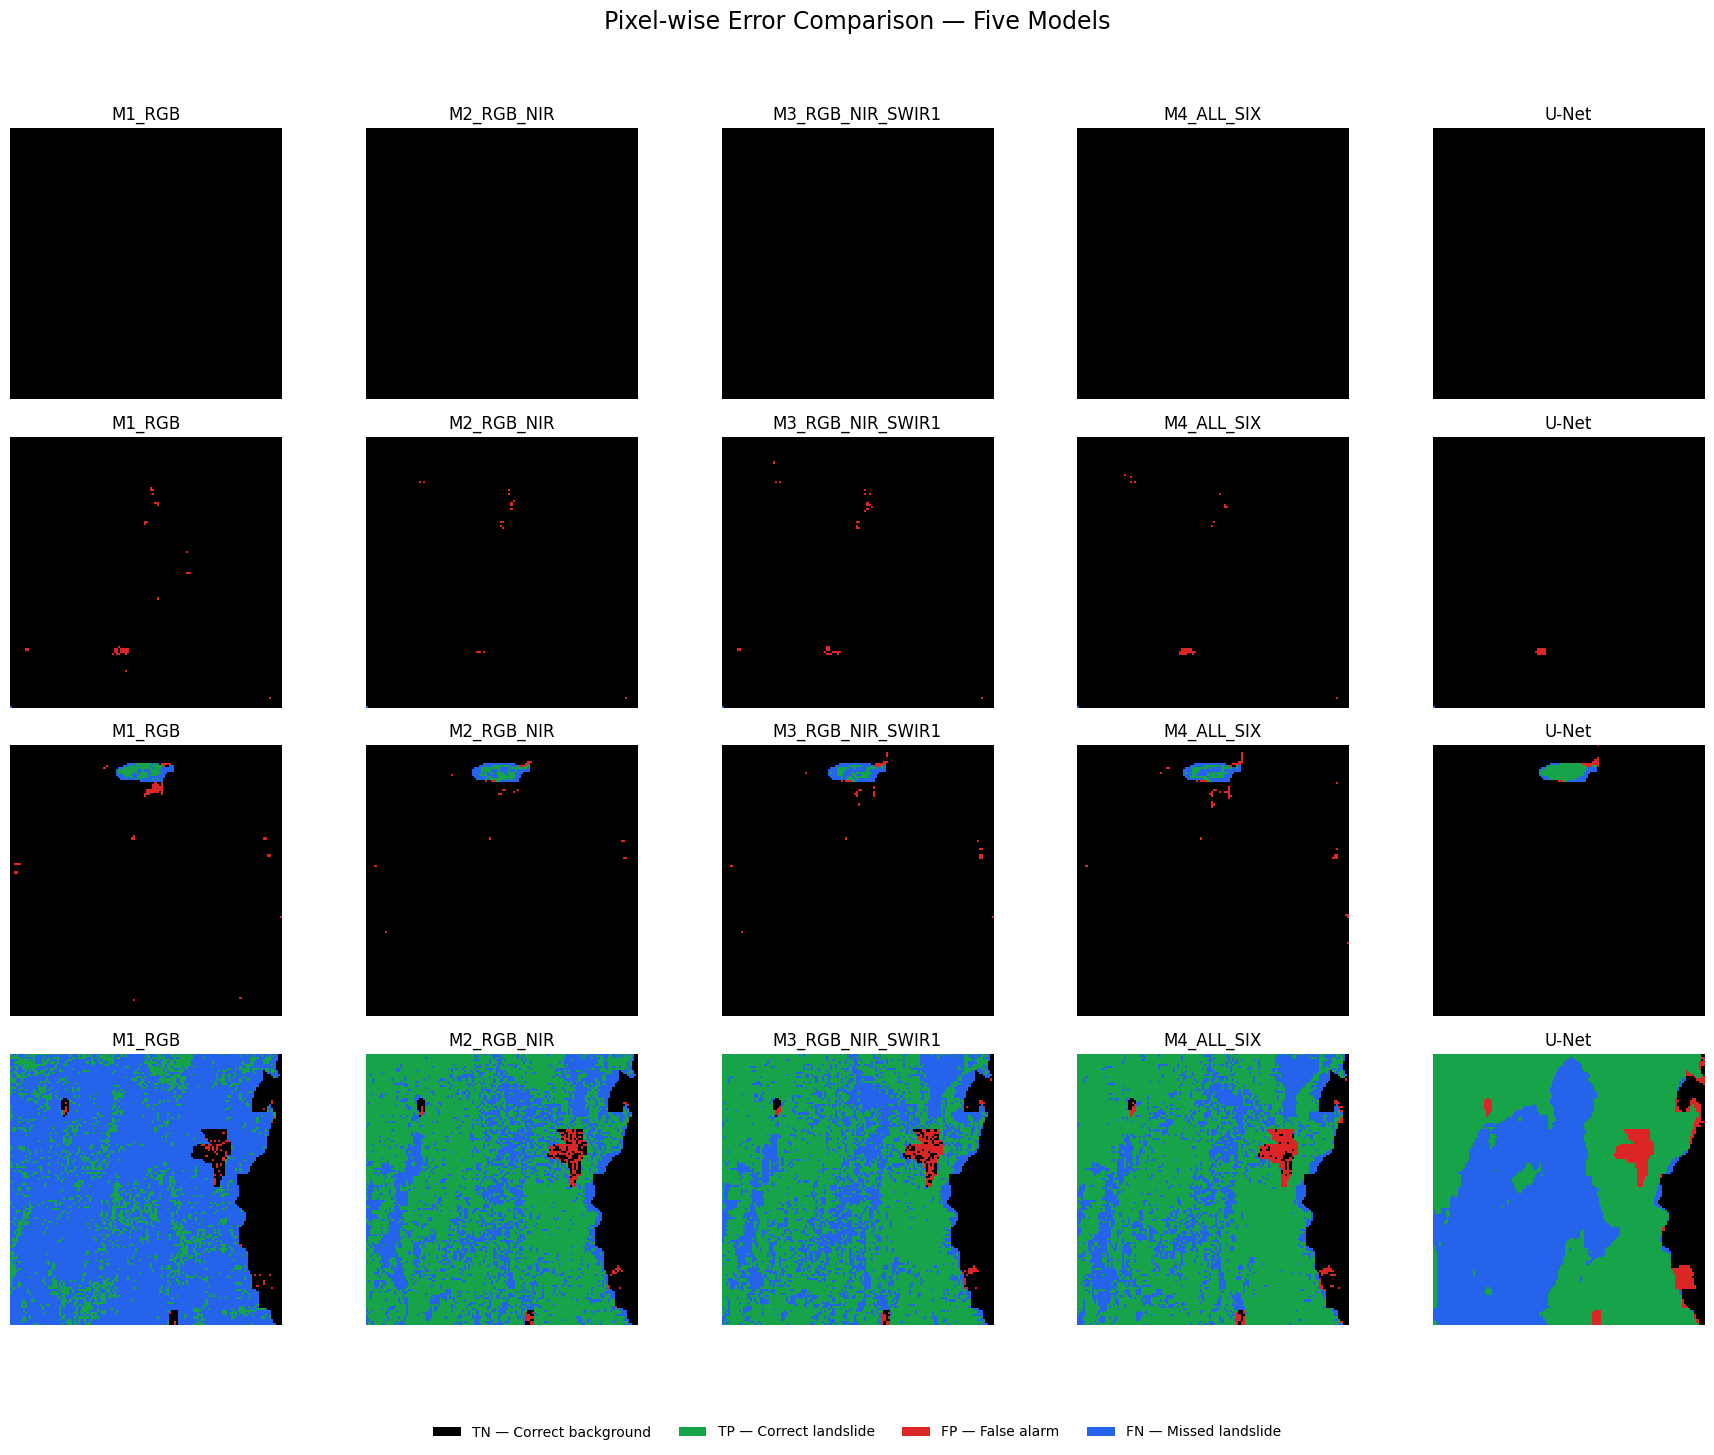

Figure 2 saved successfully.


In [ ]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# --------------------------------------------------
# 1. Define error-map colours
# --------------------------------------------------

error_cmap = ListedColormap([
    "black",       # TN = 0
    "#16A34A",     # TP = 1
    "#DC2626",     # FP = 2
    "#2563EB"      # FN = 3
])

error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    error_cmap.N
)

# --------------------------------------------------
# 2. Generate error map
# --------------------------------------------------

def make_error_map(ground_truth, prediction):

    gt = ground_truth.astype(bool)
    pred = prediction.astype(bool)

    error_map = np.zeros(gt.shape, dtype=np.uint8)

    error_map[gt & pred] = 1       # TP
    error_map[~gt & pred] = 2      # FP
    error_map[gt & ~pred] = 3      # FN

    return error_map

# --------------------------------------------------
# 3. Plot all models
# --------------------------------------------------

model_names = [
    "M1_RGB",
    "M2_RGB_NIR",
    "M3_RGB_NIR_SWIR1",
    "M4_ALL_SIX",
    "U-Net"
]

fig, axes = plt.subplots(
    len(selected), len(model_names),
    figsize=(18, 3.5 * len(selected))
)

if len(selected) == 1:
    axes = axes[np.newaxis, :]

for row, idx in enumerate(selected):

    gt = test_masks[idx]

    for col, model_name in enumerate(model_names):

        pred = predictions[model_name][idx]

        error_map = make_error_map(gt, pred)

        axes[row, col].imshow(
            error_map,
            cmap=error_cmap,
            norm=error_norm,
            interpolation="nearest"
        )

        axes[row, col].set_title(model_name)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"Patch {idx}\n{fractions[idx]*100:.2f}% landslide",
        fontsize=10
    )

# --------------------------------------------------
# 4. Add common legend
# --------------------------------------------------

legend_elements = [
    Patch(facecolor="black", label="TN — Correct background"),
    Patch(facecolor="#16A34A", label="TP — Correct landslide"),
    Patch(facecolor="#DC2626", label="FP — False alarm"),
    Patch(facecolor="#2563EB", label="FN — Missed landslide")
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.02),
    frameon=False
)

plt.suptitle(
    "Pixel-wise Error Comparison — Five Models",
    fontsize=17,
    y=1.01
)

plt.tight_layout(rect=[0, 0.06, 1, 0.98])

plt.savefig(
    "/content/Figure_2_Error_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 saved successfully.")


M1_RGB
[[12511828   347841]
 [  145135   102396]]

M2_RGB_NIR
[[12665127   194542]
 [  121894   125637]]

M3_RGB_NIR_SWIR1
[[12667643   192026]
 [  126808   120723]]

M4_ALL_SIX
[[12611699   247970]
 [  115901   131630]]

U-Net
[[12697982   161687]
 [  110205   137326]]


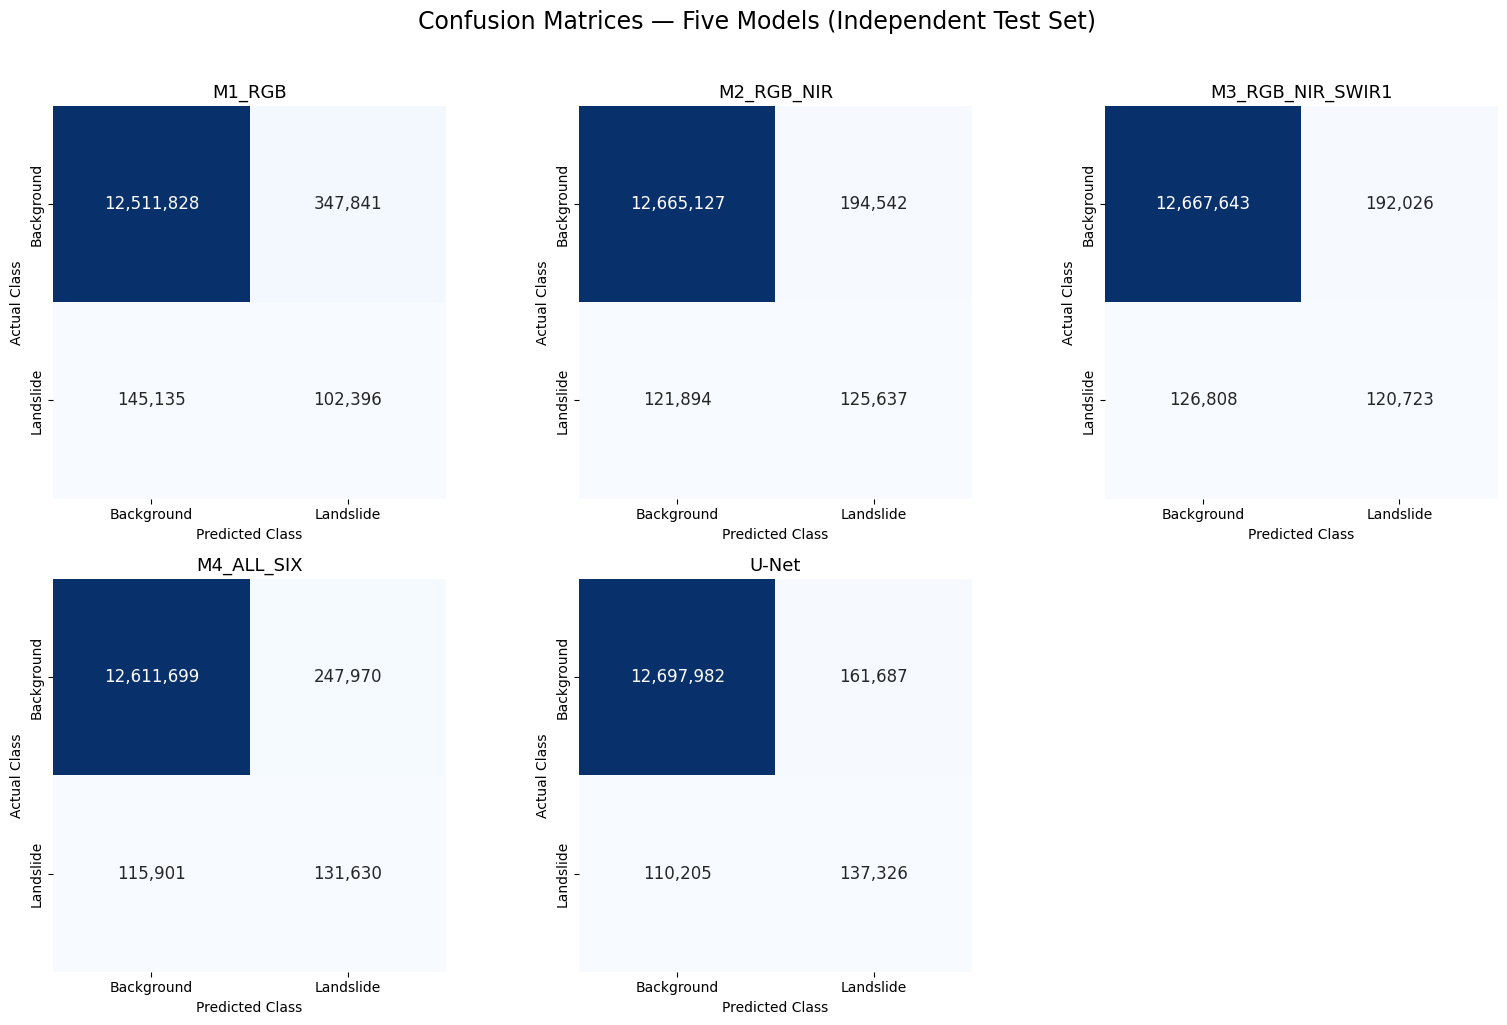

Confusion matrices saved successfully.


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

model_names = [
    "M1_RGB",
    "M2_RGB_NIR",
    "M3_RGB_NIR_SWIR1",
    "M4_ALL_SIX",
    "U-Net"
]

# --------------------------------------------------
# 1. Calculate confusion matrices
# --------------------------------------------------

confusion_matrices = {}

gt = test_masks.ravel().astype(np.uint8)

for model_name in model_names:

    pred = predictions[model_name].ravel().astype(np.uint8)

    cm = confusion_matrix(
        gt,
        pred,
        labels=[0, 1]
    )

    confusion_matrices[model_name] = cm

    print(f"\n{model_name}")
    print(cm)

# --------------------------------------------------
# 2. Plot all five confusion matrices
# --------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, model_name in enumerate(model_names):

    cm = confusion_matrices[model_name]

    sns.heatmap(
        cm,
        annot=True,
        fmt=",",
        cmap="Blues",
        cbar=False,
        square=True,
        xticklabels=["Background", "Landslide"],
        yticklabels=["Background", "Landslide"],
        ax=axes[i],
        annot_kws={"size": 12}
    )

    axes[i].set_title(model_name, fontsize=13)
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("Actual Class")

# Remove unused sixth panel
fig.delaxes(axes[5])

plt.suptitle(
    "Confusion Matrices — Five Models (Independent Test Set)",
    fontsize=17,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "/content/Figure_3_Confusion_Matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully.")

In [ ]:
import pandas as pd

cm_results = []

for model_name, cm in confusion_matrices.items():

    tn, fp, fn, tp = cm.ravel()

    cm_results.append({
        "Model": model_name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

cm_df = pd.DataFrame(cm_results)

display(cm_df)

cm_df.to_csv(
    "/content/Confusion_Matrix_Values.csv",
    index=False
)

print("Confusion matrix values saved.")

,Model,TN,FP,FN,TP
0,M1_RGB,12511828,347841,145135,102396
1,M2_RGB_NIR,12665127,194542,121894,125637
2,M3_RGB_NIR_SWIR1,12667643,192026,126808,120723
3,M4_ALL_SIX,12611699,247970,115901,131630
4,U-Net,12697982,161687,110205,137326


Confusion matrix values saved.


TEST SET PERFORMANCE


,Model,Precision,Recall,F1,IoU
0,M1_RGB,0.2274,0.4137,0.2935,0.1720
1,M2_RGB_NIR,0.3924,0.5076,0.4426,0.2842
2,M3_RGB_NIR_SWIR1,0.3860,0.4877,0.4309,0.2746
3,M4_ALL_SIX,0.3468,0.5318,0.4198,0.2657
4,U-Net,0.4593,0.5548,0.5025,0.3356


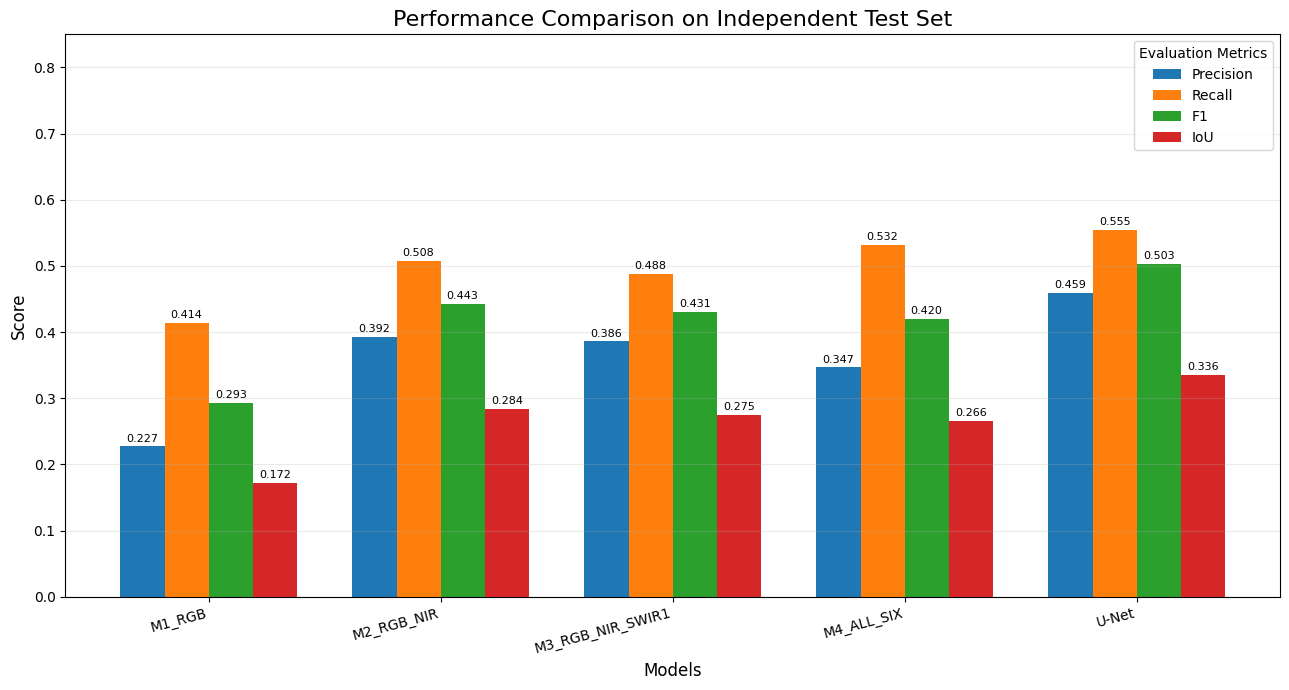

Figure 4 and final test metrics CSV saved.


In [ ]:
# --------------------------------------------------
# 1. Define models
# --------------------------------------------------

model_names = [
    "M1_RGB",
    "M2_RGB_NIR",
    "M3_RGB_NIR_SWIR1",
    "M4_ALL_SIX",
    "U-Net"
]

gt = test_masks.astype(bool)

# --------------------------------------------------
# 2. Calculate test metrics
# --------------------------------------------------

results = []

for model_name in model_names:

    pred = predictions[model_name].astype(bool)

    TP = np.sum(pred & gt)
    FP = np.sum(pred & ~gt)
    FN = np.sum(~pred & gt)
    TN = np.sum(~pred & ~gt)

    precision = TP / (TP + FP + 1e-10)
    recall = TP / (TP + FN + 1e-10)

    f1 = (
        2 * precision * recall /
        (precision + recall + 1e-10)
    )

    iou = TP / (TP + FP + FN + 1e-10)

    results.append({
        "Model": model_name,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN
    })

results_df = pd.DataFrame(results)

# --------------------------------------------------
# 3. Display numerical results
# --------------------------------------------------

metric_columns = ["Precision", "Recall", "F1", "IoU"]

print("TEST SET PERFORMANCE")
display(
    results_df[["Model"] + metric_columns].round(4)
)

# --------------------------------------------------
# 4. Plot grouped bar chart
# --------------------------------------------------

x = np.arange(len(model_names))
width = 0.19

fig, ax = plt.subplots(figsize=(13, 7))

for i, metric in enumerate(metric_columns):

    offset = (i - 1.5) * width

    bars = ax.bar(
        x + offset,
        results_df[metric],
        width,
        label=metric
    )

    # Value labels
    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=2,
        fontsize=8
    )

ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Models", fontsize=12)

ax.set_title(
    "Performance Comparison on Independent Test Set",
    fontsize=16
)

ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha="right")

ax.set_ylim(0, 0.85)
ax.legend(title="Evaluation Metrics")

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "/content/Figure_4_Metric_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 5. Save complete results
# --------------------------------------------------

results_df.to_csv(
    "/content/Final_Test_Metrics.csv",
    index=False
)

print("Figure 4 and final test metrics CSV saved.")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


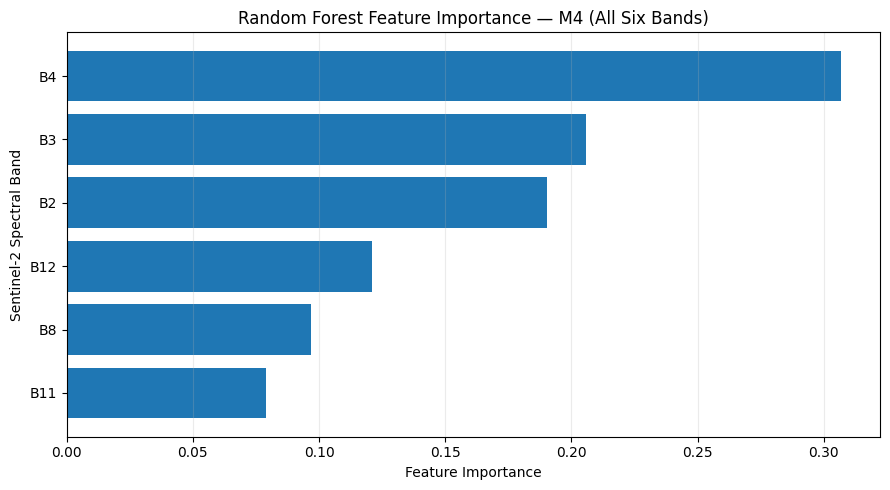

Saved: RF_Band_Importance.png

M4 Band Importance:
B2: 0.19049
B3: 0.20586
B4: 0.30692
B8: 0.09697
B11: 0.07897
B12: 0.12079

Matched training image-mask pairs: 3799
Processed 500/3799 images
Processed 1000/3799 images
Processed 1500/3799 images
Processed 2000/3799 images
Processed 2500/3799 images
Processed 3000/3799 images
Processed 3500/3799 images


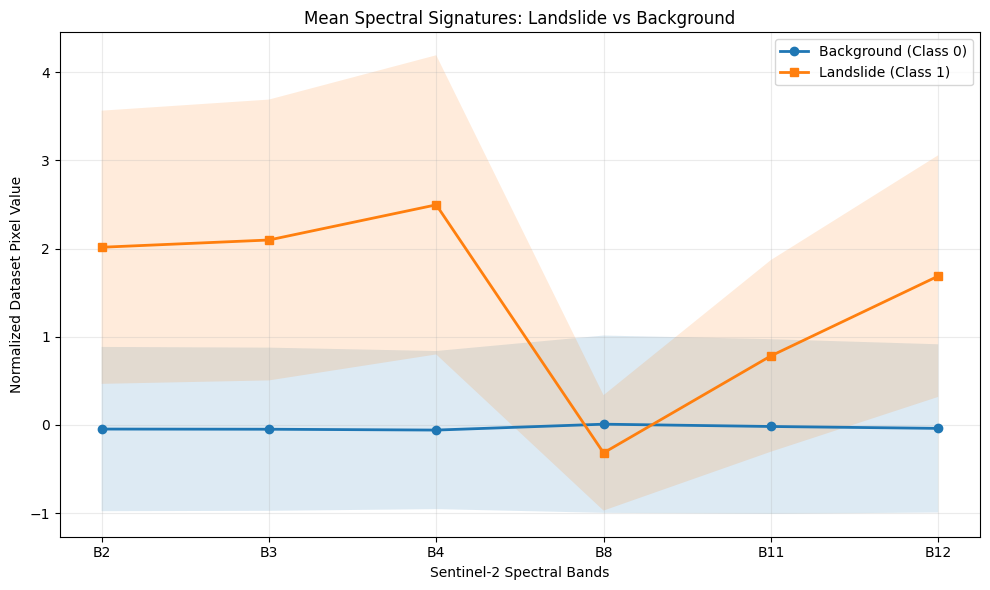


Saved: Spectral_Signatures.png

Class pixel counts:
Background: 60800026
Landslide: 1442790

Mean spectral values:
B2: Background = -0.0478, Landslide = 2.0145
B3: Background = -0.0498, Landslide = 2.0968
B4: Background = -0.0592, Landslide = 2.4956
B8: Background = 0.0075, Landslide = -0.3179
B11: Background = -0.0186, Landslide = 0.7821
B12: Background = -0.0400, Landslide = 1.6873

Both figures generated successfully.


In [ ]:
# ============================================================
# PATHS AND CONFIGURATION
# ============================================================

BASE = Path("/content/Data_Normalized/TrainData")
IMG_DIR = BASE / "img"
MASK_DIR = BASE / "mask"

MODEL_PATH = Path("/content/Ablation_Results/M4_ALL_SIX.joblib")
OUTPUT_DIR = Path("/content")

BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]

# ============================================================
# FIGURE 1: RANDOM FOREST BAND IMPORTANCE
# ============================================================

# Upload the M4 model if it is not already in Colab
if not MODEL_PATH.exists():
    from google.colab import files

    print("Upload M4_ALL_SIX.joblib")
    uploaded = files.upload()

    uploaded_name = next(
        (name for name in uploaded if name.endswith(".joblib")),
        None
    )

    if uploaded_name is None:
        raise FileNotFoundError("No .joblib model was uploaded.")

    MODEL_PATH = Path("/content") / uploaded_name

# Load M4 model
m4_model = joblib.load(MODEL_PATH)

# Extract feature importance
importance = m4_model.feature_importances_

if len(importance) != 6:
    raise ValueError(
        f"Expected 6 feature importances, got {len(importance)}"
    )

# Sort for plotting
order = np.argsort(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    [BANDS[i] for i in order],
    importance[order]
)

plt.xlabel("Feature Importance")
plt.ylabel("Sentinel-2 Spectral Band")
plt.title("Random Forest Feature Importance — M4 (All Six Bands)")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "RF_Band_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: RF_Band_Importance.png")

# Print numerical values too
print("\nM4 Band Importance:")
for band, value in zip(BANDS, importance):
    print(f"{band}: {value:.5f}")


# ============================================================
# FIGURE 2: LANDSLIDE VS BACKGROUND SPECTRAL SIGNATURES
# ============================================================

if not IMG_DIR.exists() or not MASK_DIR.exists():
    raise FileNotFoundError(
        "Training image/mask directories not found. "
        "Check BASE, IMG_DIR and MASK_DIR."
    )

# Match files by numeric ID
def get_id(filename):
    match = re.search(r"(\d+)", filename.stem)
    return match.group(1) if match else None

image_files = {
    get_id(p): p
    for p in IMG_DIR.glob("*.h5")
    if get_id(p) is not None
}

mask_files = {
    get_id(p): p
    for p in MASK_DIR.glob("*.h5")
    if get_id(p) is not None
}

common_ids = sorted(
    set(image_files) & set(mask_files),
    key=int
)

print("\nMatched training image-mask pairs:", len(common_ids))

if len(common_ids) == 0:
    raise ValueError("No matching image-mask pairs found.")

# Streaming statistics: avoid loading the whole dataset into RAM
class_sum = {
    0: np.zeros(6, dtype=np.float64),
    1: np.zeros(6, dtype=np.float64)
}

class_sum_sq = {
    0: np.zeros(6, dtype=np.float64),
    1: np.zeros(6, dtype=np.float64)
}

class_count = {0: 0, 1: 0}

for n, image_id in enumerate(common_ids, start=1):

    with h5py.File(image_files[image_id], "r") as f:
        image = f["img"][:].astype(np.float32)

    with h5py.File(mask_files[image_id], "r") as f:
        mask = f["mask"][:]

    if image.shape[-1] != 6:
        raise ValueError(
            f"{image_files[image_id].name}: expected 6 bands, "
            f"got shape {image.shape}"
        )

    # Calculate statistics separately for background and landslide
    for cls in [0, 1]:

        pixels = image[mask == cls]

        if pixels.size == 0:
            continue

        class_sum[cls] += pixels.sum(axis=0, dtype=np.float64)
        class_sum_sq[cls] += np.square(
            pixels.astype(np.float64)
        ).sum(axis=0)

        class_count[cls] += pixels.shape[0]

    if n % 500 == 0:
        print(f"Processed {n}/{len(common_ids)} images")

# Calculate means and standard deviations
means = {}
stds = {}

for cls in [0, 1]:

    if class_count[cls] == 0:
        raise ValueError(f"No pixels found for class {cls}")

    means[cls] = class_sum[cls] / class_count[cls]

    variance = (
        class_sum_sq[cls] / class_count[cls]
        - means[cls] ** 2
    )

    stds[cls] = np.sqrt(np.maximum(variance, 0))

# Plot spectral signatures
x = np.arange(len(BANDS))

plt.figure(figsize=(10, 6))

# Background signature
plt.plot(
    x,
    means[0],
    marker="o",
    linewidth=2,
    label="Background (Class 0)"
)

plt.fill_between(
    x,
    means[0] - stds[0],
    means[0] + stds[0],
    alpha=0.15
)

# Landslide signature
plt.plot(
    x,
    means[1],
    marker="s",
    linewidth=2,
    label="Landslide (Class 1)"
)

plt.fill_between(
    x,
    means[1] - stds[1],
    means[1] + stds[1],
    alpha=0.15
)

plt.xticks(x, BANDS)
plt.xlabel("Sentinel-2 Spectral Bands")
plt.ylabel("Normalized Dataset Pixel Value")
plt.title("Mean Spectral Signatures: Landslide vs Background")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Spectral_Signatures.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved: Spectral_Signatures.png")

# Print statistics for verification
print("\nClass pixel counts:")
print("Background:", class_count[0])
print("Landslide:", class_count[1])

print("\nMean spectral values:")
for i, band in enumerate(BANDS):
    print(
        f"{band}: Background = {means[0][i]:.4f}, "
        f"Landslide = {means[1][i]:.4f}"
    )

print("\nBoth figures generated successfully.")


Packing Needed Stuff !

In [ ]:
from pathlib import Path
import shutil
import zipfile
import os
from datetime import datetime

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE = Path("/content")
ARCHIVE_NAME = "Landslide4Sense_Project_Final.zip"

PACKAGE_DIR = BASE / "Landslide4Sense_Project_Final"
ZIP_PATH = BASE / ARCHIVE_NAME

# If your notebook is saved under a different name/path,
# change this variable. Leave as None to skip notebook copying.
NOTEBOOK_PATH = None

# ============================================================
# 2. CREATE PACKAGE STRUCTURE
# ============================================================

if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

folders = {
    "models": PACKAGE_DIR / "Models",
    "predictions": PACKAGE_DIR / "Predictions",
    "figures": PACKAGE_DIR / "Figures",
    "results": PACKAGE_DIR / "Results",
    "data_info": PACKAGE_DIR / "Data_Information",
    "notebook": PACKAGE_DIR / "Notebook"
}

for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)

# ============================================================
# 3. FILE COLLECTION FUNCTION
# ============================================================

copied_files = []
missing_files = []

def collect_file(source, destination_folder, required=False):

    source = Path(source)

    if source.exists() and source.is_file():

        destination = destination_folder / source.name

        shutil.copy2(source, destination)

        copied_files.append(str(destination.relative_to(PACKAGE_DIR)))

        print("COPIED:", source.name)

    else:

        missing_files.append(str(source))

        if required:
            print("MISSING REQUIRED:", source)
        else:
            print("SKIPPED:", source.name)

# ============================================================
# 4. RANDOM FOREST MODELS
# ============================================================

# rf_folder = BASE / "Ablation_Results"

# rf_models = [
#     "M1_RGB.joblib",
#     "M2_RGB_NIR.joblib",
#     "M3_RGB_NIR_SWIR1.joblib",
#     "M4_ALL_SIX.joblib"
# ]

# for filename in rf_models:
#     collect_file(
#         rf_folder / filename,
#         folders["models"],
#         required=True
#     )

# ============================================================
# 5. U-NET CHECKPOINT
# ============================================================

collect_file(
    BASE / "best_unet.pth",
    folders["models"],
    required=True
)

# ============================================================
# 6. PREDICTIONS
# ============================================================

prediction_files = [
    "all_model_predictions.npz"
]

for filename in prediction_files:
    collect_file(
        BASE / filename,
        folders["predictions"],
        required=True
    )

# ============================================================
# 7. FIGURES
# ============================================================

figure_files = [
    "Figure_1_Prediction_Comparison.png",
    "Figure_2_Error_Comparison.png",
    "Figure_3_Confusion_Matrices.png",
    "Figure_4_Metric_Comparison.png",
    "RF_Band_Importance.png",
    "Spectral_Signatures.png"
]

for filename in figure_files:
    collect_file(
        BASE / filename,
        folders["figures"]
    )

# ============================================================
# 8. NUMERICAL RESULTS
# ============================================================

result_files = [
    "Final_Test_Metrics.csv",
    "Confusion_Matrix_Values.csv",
]

for filename in result_files:
    collect_file(
        BASE / filename,
        folders["results"]
    )

# ============================================================
# 9. DATASET INFORMATION / PREPROCESSING
# ============================================================

info_files = [
    "training_sample.npz"
]

# Search common project locations
search_locations = [
    BASE / "Ablation_Results",
    BASE,
    BASE / "Data_Information"
]

for filename in info_files:

    found = False

    for location in search_locations:

        candidate = location / filename

        if candidate.exists():

            collect_file(candidate, folders["data_info"])
            found = True
            break

    if not found:
        print("INFO NOT FOUND:", filename)

# ============================================================
# 10. NOTEBOOK (OPTIONAL)
# ============================================================

if NOTEBOOK_PATH is not None:
    collect_file(
        NOTEBOOK_PATH,
        folders["notebook"]
    )
else:
    print("NOTEBOOK: skipped; set NOTEBOOK_PATH to include it.")

# ============================================================
# 11. GENERATE README
# ============================================================

readme = f"""
LANDSLIDE4SENSE PROJECT
Final Research and Reproducibility Archive

Created: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}

PROJECT
Contribution of RGB, NIR and SWIR Bands to Landslide Mapping
Sentinel-2 Spectral Band Ablation and Landslide Classification

DATASET
Landslide4Sense

Selected spectral bands:
B2, B3, B4, B8, B11, B12

RANDOM FOREST EXPERIMENTS
M1: B2, B3, B4
M2: B2, B3, B4, B8
M3: B2, B3, B4, B8, B11
M4: B2, B3, B4, B8, B11, B12

DEEP LEARNING EXTENSION
U-Net using all six selected bands.

EVALUATION
Independent test set:
800 patches

Metrics:
Precision, Recall, F1-score and IoU.

CONTENTS
Models:
Trained RF models and U-Net checkpoint.

Predictions:
Saved predictions and ground-truth masks.

Figures:
Prediction maps, spatial error maps, confusion matrices,
metric comparison and any additional completed analysis.

Results:
CSV files containing numerical evaluation results.

Data_Information:
Preprocessing and dataset information, when available.

Notebook:
Complete executable Colab notebook, if supplied.

IMPORTANT
The original Landslide4Sense dataset is not included.
The normalized image and mask dataset is also not included.
Download the original dataset separately from:
https://zenodo.org/records/10463239

Missing files are listed in the packaging output.
Check that all required analysis outputs have been generated
before treating this archive as the final research submission.
"""

(PACKAGE_DIR / "README.txt").write_text(
    readme,
    encoding="utf-8"
)

# ============================================================
# 12. CREATE ZIP ARCHIVE
# ============================================================

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=4
) as archive:

    for file in PACKAGE_DIR.rglob("*"):

        if file.is_file():

            archive.write(
                file,
                file.relative_to(BASE)
            )

# ============================================================
# 13. FINAL SUMMARY
# ============================================================

size_mb = ZIP_PATH.stat().st_size / (1024 ** 2)

print("\n" + "=" * 60)
print("PROJECT PACKAGING COMPLETE")
print("=" * 60)

print("Archive:", ZIP_PATH)
print(f"Archive size: {size_mb:.2f} MB")

print(f"\nFiles packaged: {len(copied_files)}")

for filename in copied_files:
    print("  +", filename)

print(f"\nMissing / skipped files: {len(missing_files)}")

for filename in missing_files:
    print("  -", filename)

print("\nZIP FILE READY FOR DOWNLOAD.")


COPIED: best_unet.pth
COPIED: all_model_predictions.npz
COPIED: Figure_1_Prediction_Comparison.png
COPIED: Figure_2_Error_Comparison.png
COPIED: Figure_3_Confusion_Matrices.png
COPIED: Figure_4_Metric_Comparison.png
COPIED: RF_Band_Importance.png
COPIED: Spectral_Signatures.png
COPIED: Final_Test_Metrics.csv
COPIED: Confusion_Matrix_Values.csv
COPIED: training_sample.npz
NOTEBOOK: skipped; set NOTEBOOK_PATH to include it.

PROJECT PACKAGING COMPLETE
Archive: /content/Landslide4Sense_Project_Final.zip
Archive size: 90.58 MB

Files packaged: 11
  + Models/best_unet.pth
  + Predictions/all_model_predictions.npz
  + Figures/Figure_1_Prediction_Comparison.png
  + Figures/Figure_2_Error_Comparison.png
  + Figures/Figure_3_Confusion_Matrices.png
  + Figures/Figure_4_Metric_Comparison.png
  + Figures/RF_Band_Importance.png
  + Figures/Spectral_Signatures.png
  + Results/Final_Test_Metrics.csv
  + Results/Confusion_Matrix_Values.csv
  + Data_Information/training_sample.npz

Missing / skipped fi

In [ ]:
from google.colab import files

files.download(
    "/content/Landslide4Sense_Project_Final.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>